<a href="https://colab.research.google.com/github/HebaRouk/-Build-a-ML-Workflow-For-Scones-Unlimited-On-Amazon-SageMaker/blob/main/DL_Lab0_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!ls /content/course/ai702-student/lab0

ls: cannot access '/content/course/ai702-student/lab0': No such file or directory


In [4]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [7]:
import zipfile

with zipfile.ZipFile("/content/AI702_Lab0.zip") as archive:
    archive.extractall("/content/course")

!ls /content/course
!ls /content/course/*

ai702-student
AGENTS.md     CLAUDE.md  lab.py		 README.md  uv.lock
AI_POLICY.md  lab0	 pyproject.toml  shared


In [8]:
%%writefile /content/course/ai702-student/lab0/student.py


import numpy as np
import torch


# ---------------------------------------------------------------------------
# Task 1: select columns while keeping the result 2D
# ---------------------------------------------------------------------------
def select_columns(x, column_indices):
    """Return only the requested columns of x as a 2D array (batch, len(columns))."""
    x = np.asarray(x)
    if x.ndim == 1:
        # A single sample: add the batch dimension so the result stays 2D
        x = x[np.newaxis, :]
    # Indexing with a list (not a single int) keeps the column axis
    column_indices = list(np.atleast_1d(column_indices))
    return x[:, column_indices]


# ---------------------------------------------------------------------------
# Task 2: standardize using the given (training) statistics
# ---------------------------------------------------------------------------
def standardize_columns(x, mean, standard_deviation):
    """Return (x - mean) / std as a NEW array; never modify x in place."""
    x = np.asarray(x, dtype=float)
    mean = np.asarray(mean, dtype=float)
    standard_deviation = np.asarray(standard_deviation, dtype=float)

    if np.any(standard_deviation == 0):
        raise ValueError("standard_deviation contains zero; cannot standardize.")

    # Broadcasting: (batch, features) with (features,) -> (batch, features)
    # The subtraction creates a new array, so the original x is untouched.
    return (x - mean) / standard_deviation


# ---------------------------------------------------------------------------
# Task 3: linear layer scores with NumPy
# ---------------------------------------------------------------------------
def linear_scores_numpy(x, weight, bias):
    """x: (batch, inputs), weight: (outputs, inputs), bias: (outputs,) -> (batch, outputs)."""
    x = np.asarray(x, dtype=float)
    if x.ndim == 1:
        x = x[np.newaxis, :]
    weight = np.asarray(weight, dtype=float)
    bias = np.asarray(bias, dtype=float)
    # (batch, inputs) @ (inputs, outputs) -> (batch, outputs), then bias broadcasts per row
    return x @ weight.T + bias


# ---------------------------------------------------------------------------
# Task 4: a callable linear layer object
# ---------------------------------------------------------------------------
class LinearTransform:
    """Stores weight and bias; calling the object computes the linear scores."""

    def __init__(self, weight, bias):
        self.weight = np.asarray(weight, dtype=float)
        self.bias = np.asarray(bias, dtype=float)

    def __call__(self, x):
        return linear_scores_numpy(x, self.weight, self.bias)


# ---------------------------------------------------------------------------
# Task 5: the same linear layer with PyTorch tensors
# ---------------------------------------------------------------------------
def torch_linear_scores(x, weight, bias):
    """Same as linear_scores_numpy but with torch tensors."""
    if x.dim() == 1:
        x = x.unsqueeze(0)
    return x @ weight.T + bias


# ---------------------------------------------------------------------------
# Task 6: (N, C, H, W) -> (N, H, W, C)
# ---------------------------------------------------------------------------
def rearrange_nchw_to_nhwc(images):
    """Reorder axes with permute (NOT reshape) and return a contiguous tensor."""
    return images.permute(0, 2, 3, 1).contiguous()


# ---------------------------------------------------------------------------
# Task 7: accuracy as a fraction in [0, 1]
# ---------------------------------------------------------------------------
def _to_flat_numpy(values):
    if torch.is_tensor(values):
        values = values.detach().cpu().numpy()
    return np.asarray(values).reshape(-1)


def accuracy_fraction(y_true, y_pred):
    """Fraction of matching labels. Flattening avoids the (N,1) vs (N,) broadcasting trap."""
    y_true = _to_flat_numpy(y_true)
    y_pred = _to_flat_numpy(y_pred)

    if y_true.shape != y_pred.shape:
        raise ValueError("y_true and y_pred must contain the same number of labels.")
    if y_true.size == 0:
        raise ValueError("Cannot compute accuracy of empty inputs.")

    return float(np.mean(y_true == y_pred))


Overwriting /content/course/ai702-student/lab0/student.py


In [9]:
!head -3 /content/course/ai702-student/lab0/student.py



import numpy as np


In [10]:
%cd /content/course/ai702-student
!env -u PYTHONPATH uv run --locked python lab.py test 0

/content/course/ai702-student
Using CPython 3.12.3 interpreter at: /usr/bin/python3.12
Creating virtual environment at: .venv
Installed 39 packages in 367ms
.......                                                                  [100%]
7 passed in 6.03s


In [12]:
%cd /content/course/ai702-student
!git init -q
!git config user.name "Heba Qudaih"
!git config user.email "heba.qudaih@mbzuai.ac.ae"
!git add -A
!git commit -q -m "Lab 0 core: complete student.py"
!git log --oneline -1

/content/course/ai702-student
aa416ad (HEAD -> master) Lab 0 core: complete student.py


In [13]:
!git -C /content/course/ai702-student status

On branch master
nothing to commit, working tree clean


In [14]:
!git -C /content/course/ai702-student ls-files | grep -c "^.venv/"

0


In [15]:
%cd /content/course/ai702-student
!env -u PYTHONPATH -u MPLBACKEND uv run --locked python lab.py run 0
!env -u PYTHONPATH -u MPLBACKEND uv run --locked python lab.py view 0 --no-open

/content/course/ai702-student
/content/course/ai702-student/lab0/results/core/20261023T080643-970b6a0f/index.html
View: python lab.py view 0 --stage core
/content/course/ai702-student/lab0/results/core/20261023T080643-970b6a0f/index.html


In [17]:
import glob, os

run_folders = [path for path in glob.glob("/content/course/ai702-student/lab0/results/core/*") if os.path.isdir(path)]
run = sorted(run_folders)[-1]
run_id = os.path.basename(run)
print("Latest core run:", run_id)
print("Files in this run:", sorted(os.listdir(run)))

Latest core run: 20261023T080643-970b6a0f
Files in this run: ['confusion.png', 'details.json', 'index.html', 'loss.png', 'metrics.json', 'notes_at_start.md', 'raw.npz', 'run.json', 'settings_used.json', 'source', 'validation_predictions.csv']


{
  "reported_accuracy": 97.8021978021978,
  "reported_units": "fraction between 0 and 1",
  "student_recomputed_accuracy": 0.978021978021978,
  "examples": 91
}


,sample_id,target,prediction,score_0,score_1
0,18,0,0,0.999953,0.000047
1,399,1,1,0.016072,0.983928
2,533,0,0,0.998576,0.001424
3,293,1,1,0.029027,0.970973
4,134,0,0,0.995294,0.004706


(91, 5)


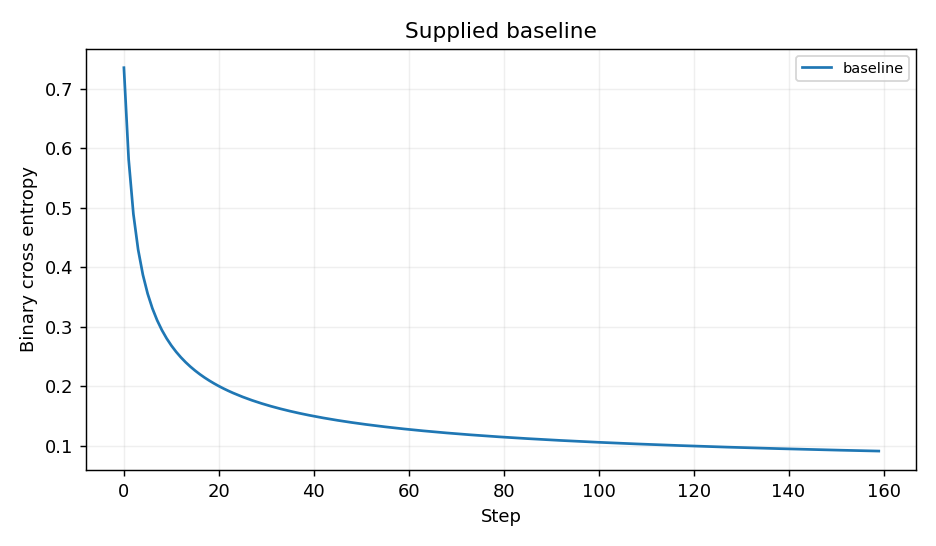

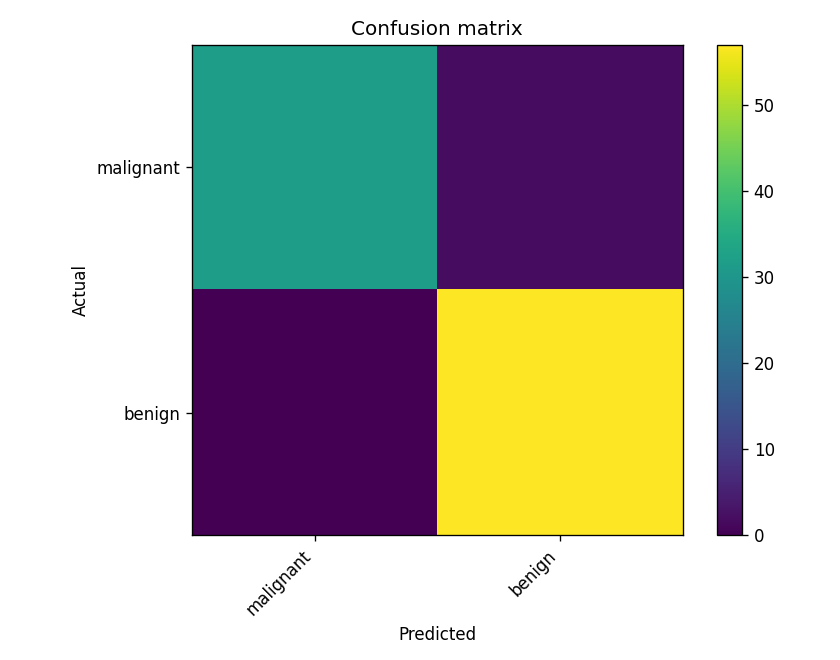

['loss', 'targets', 'predictions', 'probabilities', 'selected', 'standardized', 'numpy_scores', 'torch_scores']


In [18]:
import json, pandas as pd, numpy as np
from IPython.display import Image, display

print(json.dumps(json.load(open(f"{run}/metrics.json")), indent=2))
df = pd.read_csv(f"{run}/validation_predictions.csv")
display(df.head())
print(df.shape)
display(Image(f"{run}/loss.png")); display(Image(f"{run}/confusion.png"))
archive = np.load(f"{run}/raw.npz"); print(archive.files)

In [19]:
print(pd.crosstab(df["target"], df["prediction"], rownames=["actual"], colnames=["predicted"]))

predicted   0   1
actual           
0          32   2
1           0  57


In [20]:
import json, numpy as np, pandas as pd


metrics = json.load(open(f"{run}/metrics.json"))
df = pd.read_csv(f"{run}/validation_predictions.csv")
archive = np.load(f"{run}/raw.npz")

# 1) Recompute accuracy from the CSV columns
correct = (df["target"].to_numpy() == df["prediction"].to_numpy())
my_accuracy = correct.mean()
print("Correct:", correct.sum(), "/", len(df), "-> accuracy fraction =", my_accuracy)
print("Misclassified rows:")
print(df[~correct])

# Sanity check: prediction column should equal argmax of the score columns
argmax_pred = df[["score_0", "score_1"]].to_numpy().argmax(axis=1)
print("prediction == argmax(scores) for all rows:", (argmax_pred == df["prediction"]).all())

# 2) Compare with the reported number and its unit
reported = metrics["reported_accuracy"]
print("\nReported:", reported, "| unit:", metrics["reported_units"])
print("Reported is a valid fraction (0..1):", 0 <= reported <= 1)
print("Reported / 100 matches my fraction:", np.isclose(reported / 100, my_accuracy))

# 3) Cross-check CSV against raw.npz
print("\nCSV targets == raw targets:", np.array_equal(df["target"].to_numpy(), archive["targets"].reshape(-1)))
print("CSV predictions == raw predictions:", np.array_equal(df["prediction"].to_numpy(), archive["predictions"].reshape(-1)))

# 4) NumPy vs PyTorch scores
numpy_scores = archive["numpy_scores"]
torch_scores = archive["torch_scores"]
print("\nShapes:", numpy_scores.shape, torch_scores.shape, "| dtypes:", numpy_scores.dtype, torch_scores.dtype)
difference = np.abs(numpy_scores - torch_scores)
print("Max abs difference:", difference.max())
print("allclose (atol=1e-6):", np.allclose(numpy_scores, torch_scores, atol=1e-6))
print("Same argmax class:", np.array_equal(numpy_scores.argmax(1), torch_scores.argmax(1)))

# details.json: print it to see what it claims about the two implementations
details = json.load(open(f"{run}/details.json"))
print("\ndetails.json:")
print(json.dumps(details, indent=2)[:3000])

Correct: 89 / 91 -> accuracy fraction = 0.978021978021978
Misclassified rows:
    sample_id  target  prediction   score_0   score_1
20         40       0           1  0.134042  0.865958
77        263       0           1  0.270002  0.729998
prediction == argmax(scores) for all rows: True

Reported: 97.8021978021978 | unit: fraction between 0 and 1
Reported is a valid fraction (0..1): False
Reported / 100 matches my fraction: True

CSV targets == raw targets: True
CSV predictions == raw predictions: True

Shapes: (4, 2) (4, 2) | dtypes: float64 float64
Max abs difference: 0.0
allclose (atol=1e-6): True
Same argmax class: True

details.json:
{
  "note": "One metric above is deliberately inconsistent. Use the CSV to explain why.",
  "array_tensor_max_difference": 0.0,
  "permuted_shape": [
    2,
    2,
    4,
    3
  ],
  "view_reshape_demonstration": {
    "original_shape": [
      2,
      3,
      4
    ],
    "transposed_shape": [
      2,
      4,
      3
    ],
    "transposed_is_co

In [23]:
%cd /content/course/ai702-student
!env -u PYTHONPATH -u MPLBACKEND uv run --locked python lab.py package 0 --run-id {run_id}

/content/course/ai702-student
SHA256: 3560325fe74bdd4cb8c4f75b7fde36a5d6bd34404f8a8502573383dd59840790
Submit this stage ZIP and the matching stage commit to the LMS. Keep the core submission before editing for transfer.
/content/course/ai702-student/lab0/submissions/core-20261023T080643-970b6a0f.zip


In [25]:
from google.colab import files
files.download(f"/content/course/ai702-student/lab0/submissions/core-{run_id}.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
!grep -rn "transfer.json\|transfer.sig\|not been released" /content/course/ai702-student --include=*.py | head -20

/content/course/ai702-student/shared/integrity.py:130:                    'transfer.json',
/content/course/ai702-student/shared/integrity.py:131:                    'transfer.sig',
/content/course/ai702-student/shared/integrity.py:137:        transfer = root / f'lab{number}/transfer.json'
/content/course/ai702-student/shared/integrity.py:152:    path = checked_relative(root, f'lab{number}/transfer.json')
/content/course/ai702-student/shared/integrity.py:153:    checked_relative(root, f'lab{number}/transfer.sig')
/content/course/ai702-student/shared/integrity.py:155:        raise IntegrityError('The transfer task has not been released yet')
/content/course/ai702-student/shared/common.py:115:            paths.extend((ROOT / f'lab{number}' / name for name in ('transfer.json', 'transfer.sig', 'repair.py') if (ROOT / f'lab{number}' / name).is_file()))
/content/course/ai702-student/shared/evidence.py:124:            required |= {f'source/lab{lab}/transfer.json', f'source/lab{lab}/transfer.si

In [29]:
!cp /content/transfer.json /content/transfer.sig /content/course/ai702-student/lab0/
!ls /content/course/ai702-student/lab0/

notes.md     README.md	run.py	       student.py   test_lab0.py   transfer.sig
__pycache__  results	settings.json  submissions  transfer.json


In [30]:
%cd /content/course/ai702-student
!env -u PYTHONPATH -u MPLBACKEND uv run --locked python lab.py transfer 0

/content/course/ai702-student
The baseline split changed. Recompute accuracy from its new prediction file and explain whether the original unit inconsistency remains.
Settings for this condition: {'seed': 711}
Run: python lab.py run 0 --stage transfer


In [31]:
!env -u PYTHONPATH -u MPLBACKEND uv run --locked python lab.py run 0 --stage transfer

/content/course/ai702-student/lab0/results/transfer/20261023T082126-884c2e59/index.html
View: python lab.py view 0 --stage transfer


In [32]:
import glob, os, json
import numpy as np, pandas as pd

transfer_folders = [path for path in glob.glob("/content/course/ai702-student/lab0/results/transfer/*") if os.path.isdir(path)]
transfer_run = sorted(transfer_folders)[-1]
transfer_run_id = os.path.basename(transfer_run)
print("Latest transfer run:", transfer_run_id)

transfer_metrics = json.load(open(f"{transfer_run}/metrics.json"))
print(json.dumps(transfer_metrics, indent=2))
print(json.dumps(json.load(open(f"{transfer_run}/settings_used.json")), indent=2))

transfer_df = pd.read_csv(f"{transfer_run}/validation_predictions.csv")
print(transfer_df.shape)

# Recompute accuracy from the new prediction file
transfer_correct = transfer_df["target"].to_numpy() == transfer_df["prediction"].to_numpy()
transfer_accuracy = transfer_correct.mean()
print("\nCorrect:", transfer_correct.sum(), "/", len(transfer_df), "-> accuracy fraction =", transfer_accuracy)
print("Misclassified rows:")
print(transfer_df[~transfer_correct])
print(pd.crosstab(transfer_df["target"], transfer_df["prediction"], rownames=["actual"], colnames=["predicted"]))

# Does the unit inconsistency remain?
transfer_reported = transfer_metrics["reported_accuracy"]
print("\nReported:", transfer_reported, "| unit:", transfer_metrics["reported_units"])
print("Reported is a valid fraction (0..1):", 0 <= transfer_reported <= 1)
print("Reported / 100 matches my fraction:", np.isclose(transfer_reported / 100, transfer_accuracy))

Latest transfer run: 20261023T082126-884c2e59
{
  "reported_accuracy": 96.7032967032967,
  "reported_units": "fraction between 0 and 1",
  "student_recomputed_accuracy": 0.967032967032967,
  "examples": 91
}
{
  "seed": 711,
  "device": "cpu"
}
(91, 5)

Correct: 88 / 91 -> accuracy fraction = 0.967032967032967
Misclassified rows:
    sample_id  target  prediction   score_0   score_1
24        135       0           1  0.100849  0.899151
38        414       0           1  0.485967  0.514033
77        128       1           0  0.599710  0.400290
predicted   0   1
actual           
0          32   2
1           1  56

Reported: 96.7032967032967 | unit: fraction between 0 and 1
Reported is a valid fraction (0..1): False
Reported / 100 matches my fraction: True


In [44]:
%%writefile /content/course/ai702-student/lab0/notes.md
# Lab 0 notes

## Expectation (complete before running)

I expected the NumPy and PyTorch linear scores to be identical (or equal within
floating-point tolerance), because both compute the same affine map `x @ W.T + b`
on the same float64 inputs. I also expected the recomputed accuracy to lie in [0, 1],
since accuracy is defined as the fraction of correctly classified examples.
An observation that would challenge this: a non-zero max difference between the
two score arrays, or a reported accuracy whose value disagrees with its stated unit.

## Experiment

Core stage: baseline settings as recorded in `settings_used.json` (device: cpu).
Transfer stage: released condition `{'seed': 711}`, which changes the train/validation split.
Kept fixed: `student.py` (commit aa416ad), model, data source, and device (cpu).

Evidence (raw measurements):
- Core: `lab0/results/core/20261023T080643-970b6a0f/`
  (`metrics.json`, `validation_predictions.csv`, `raw.npz`, `details.json`)
- Transfer: `lab0/results/transfer/20261023T082126-884c2e59/`
  (`metrics.json`, `validation_predictions.csv`, `settings_used.json`)

## Explanation

NumPy/PyTorch difference: NumPy works on `ndarray` objects, while PyTorch works on
`Tensor` objects that also carry a device and can track gradients. Their default float
types also differ (NumPy defaults to float64, new PyTorch tensors to float32), so the
same formula can give slightly different results if the dtypes are not matched. Here
both score arrays are float64 with shape (4, 2), and `raw.npz` gives a max absolute
difference of 0.0 between `numpy_scores` and `torch_scores`, with the same argmax class
for every row.

Shape / memory-layout issue: `permute` and `transpose` only change strides; they do not
move data, so the result is non-contiguous. In `details.json`, a (2, 3, 4) tensor
transposed to (2, 4, 3) has `transposed_is_contiguous: false`, and `view` fails on it,
while `reshape` (which copies when needed) succeeds with shape [24]. This is why
`rearrange_nchw_to_nhwc` calls `.contiguous()` after `permute(0, 2, 3, 1)`; the recorded
permuted shape is [2, 2, 4, 3] (N, H, W, C).

Accuracy-unit inconsistency: `metrics.json` reports `reported_accuracy = 97.8021978021978`
with `reported_units = "fraction between 0 and 1"`. Recomputing from
`validation_predictions.csv` gives 89 / 91 correct = 0.978021978021978, which matches
`student_recomputed_accuracy`. The reported value lies outside [0, 1] and equals
100 x 0.978, so it is a percentage labelled as a fraction. The two misclassified rows
are sample_id 40 and 263 (target 0, predicted 1). The CSV targets and predictions match
`raw.npz` exactly, and every prediction equals the argmax of `score_0` and `score_1`.

## Transfer condition

Released condition: `{'seed': 711}`, a different train/validation split.
Change made: none to the code; I ran `python lab.py run 0 --stage transfer` with the
released settings only.

Result: recomputing from the new `validation_predictions.csv` gives 88 / 91 correct =
0.967032967032967. The reported value is 96.7032967032967, again labelled as a
"fraction between 0 and 1", outside [0, 1], and equal to 100 x 0.967. The misclassified
rows changed: sample_id 135 and 414 (target 0, predicted 1) and sample_id 128
(target 1, predicted 0).

What the comparison supports: the unit inconsistency remains under a different split,
so it is a systematic reporting issue (the fraction is multiplied by 100) rather than
a property of one particular split. The accuracy change from 0.978 to 0.967 corresponds
to a single example on a 91-example validation set, so this one comparison does not
show a meaningful difference between the two splits.

## Assistance declaration

Record permitted conceptual preparation and TA help. Confirm no AI assistance was
used for assessed implementation, debugging, experiments or explanations. Disclose
any exception to the teaching team. Do not attach unrelated personal conversations.

Sources used: AI7102 Week 1 Lecture 1 (course introduction and history of neural networks) and Lecture 2 (perceptrons, multi-layer perceptrons, and what neural networks can represent) by Muhammad Haris. Lecture 2’s description of a perceptron as a weighted sum of inputs plus a bias is the concept behind the linear-score functions (x @ W.T + b).

Overwriting /content/course/ai702-student/lab0/notes.md


In [45]:
print(open("/content/course/ai702-student/lab0/notes.md").read())

# Lab 0 notes

## Expectation (complete before running)

I expected the NumPy and PyTorch linear scores to be identical (or equal within
floating-point tolerance), because both compute the same affine map `x @ W.T + b`
on the same float64 inputs. I also expected the recomputed accuracy to lie in [0, 1],
since accuracy is defined as the fraction of correctly classified examples.
An observation that would challenge this: a non-zero max difference between the
two score arrays, or a reported accuracy whose value disagrees with its stated unit.

## Experiment

Core stage: baseline settings as recorded in `settings_used.json` (device: cpu).
Transfer stage: released condition `{'seed': 711}`, which changes the train/validation split.
Kept fixed: `student.py` (commit aa416ad), model, data source, and device (cpu).

Evidence (raw measurements):
- Core: `lab0/results/core/20261023T080643-970b6a0f/`
  (`metrics.json`, `validation_predictions.csv`, `raw.npz`, `details.json`)
- Transfer: `lab0/resu

In [49]:
import zipfile

zip_path = f"/content/course/ai702-student/lab0/submissions/transfer-{transfer_run_id}.zip"
with zipfile.ZipFile(zip_path) as archive:
    for name in archive.namelist():
        if name.endswith("notes.md"):
            print("=" * 60, name)
            print(archive.read(name).decode("utf-8"))

In [50]:
from google.colab import files
files.download(f"/content/course/ai702-student/lab0/submissions/core-{run_id}.zip")
files.download(f"/content/course/ai702-student/lab0/submissions/transfer-{transfer_run_id}.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [51]:
!cp -r /content/course/ai702-student /content/drive/MyDrive/ai702-lab0-backup

In [52]:
%cd /content/course/ai702-student

print("All commits:")
!git log --oneline

print("\nCore stage commit:")
!git log --format="%h  |  %H  |  %s" --grep="Lab 0 core"

print("\nTransfer stage commit:")
!git log --format="%h  |  %H  |  %s" --grep="Lab 0 transfer"

/content/course/ai702-student
All commits:
bd948fc (HEAD -> master) Lab 0 transfer: seed 711 analysis
aa416ad Lab 0 core: complete student.py

Core stage commit:
aa416ad  |  aa416adc1e02adc9df0d9e2a395633dc5a0ffcbe  |  Lab 0 core: complete student.py

Transfer stage commit:
bd948fc  |  bd948fc5f3fed0847ad112bcf8a02aeb6bb1b5c8  |  Lab 0 transfer: seed 711 analysis


In [53]:
!git -C /content/course/ai702-student status --short

In [54]:
%cd /content/course
!zip -qr /content/ai702-student-full.zip ai702-student -x "ai702-student/.venv/*" "*/__pycache__/*"
!ls -lh /content/ai702-student-full.zip

from google.colab import files
files.download("/content/ai702-student-full.zip")

/content/course
-rw-r--r-- 1 root root 432K Oct 23 09:17 /content/ai702-student-full.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>